# Maximum mean discrepancy (MMD)

Here we provide some further background into
the maximum mean discrepancy loss. Which we
provide as built-in loss function for computing
the discrepancy between model-simulated and expert-
elicited statistics.

(in progress)
## Conceptual Background
Biased, squared maximum mean discrepancy proposed by Gretton et al. (2012)

$$
MMD_b^2 = \frac{1}{m^2} \sum_{i,j=1}^m k(x_i,x_j)-\frac{2}{mn}\sum_{i,j=1}^{m,n}
k(x_i,y_j)+\frac{1}{n^2}\sum_{i,j=1}^n k(y_i,y_j)
$$
### Kernel choices
**Energy kernel**
Suggested by Feydy et al. (2019), Feydy (2020)

$k(x,y) = -||x-y||$

**Gaussian kernel**

$k(x,y) = \exp\left(-\frac{||x-y||^2}{2\sigma^2}\right)$
whereby
$||x-y||^2 = x^\top x - 2xy + y^\top y$
### Example: MMD with energy kernel
$$
MMD_b^2 = \frac{1}{m^2} \sum_{i,j=1}^m
\underbrace{-||x_i-x_j||}_{A}-\frac{2}{mn}\sum_{i,j=1}^{m,n}
\underbrace{-||x_i-y_j||}_{B}+\frac{1}{n^2}\sum_{i,j=1}^n
\underbrace{-||y_i-y_j||}_{C}
$$
consider $x, y$ to be column vectors.

**Step 1: Compute the euclidean distance**
$$
\begin{align*}
\textbf{A :} &-||x_i-x_j||= -\sqrt{ \left(||x_i-x_j||^2 \right)} =
-\sqrt{\left( x_i x_i^\top - 2x_i x_j^\top + x_j x_j^\top \right)} \\
\textbf{B :} &-||x_i-y_j||=-\sqrt{\left(||x_i-y_j||^2\right)} =
-\sqrt{\left(x_i x_i^\top - 2x_i y_j^\top + y_j y_j^\top\right)} \\
\textbf{C :} &-||y_i-y_j||=-\sqrt{\left(||y_i-y_j||^2\right)} =
-\sqrt{\left(y_i y_i^\top - 2y_i y_j^\top + y_j y_j^\top\right)}
\end{align*}
$$

**Step 2: Compute the biased squared maximum mean discrepancy**
$$
MMD_b^2 = \frac{1}{m^2} \sum_{i,j=1}^m A -\frac{2}{mn}\sum_{i,j=1}^{m,n} B
+\frac{1}{n^2}\sum_{i,j=1}^n C
$$

**References:**

+ Feydy, J., Séjourné, T., Vialard, F. X., Amari, S. I., Trouvé, A., & Peyré,
G. (2019, April). Interpolating between optimal transport and mmd using sinkhorn
divergences. In The 22nd International Conference on Artificial Intelligence and
Statistics (pp. 2681-2690). PMLR.
[PDF](http://proceedings.mlr.press/v89/feydy19a/feydy19a.pdf)
+ Feydy, J. (2020). Geometric data analysis, beyond convolutions. Applied Mathematics,
3. PhD Thesis. [PDF](https://www.jeanfeydy.com/geometric_data_analysis.pdf)
+ Gretton, A., Borgwardt, K. M., Rasch, M. J., Schölkopf, B., & Smola, A. (2012).
A kernel two-sample test. The Journal of Machine Learning Research, 13(1), 723-773.
[PDF](https://www.jmlr.org/papers/volume13/gretton12a/gretton12a.pdf?ref=https://githubhelp.com)

## Implementation
### Imports

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import tensorflow as tf
import tensorflow_probability as tfp

from elicito.losses import MMD2

tfd = tfp.distributions

### Example simulations
#### Numeric toy example
with one-dimensional samples $X\sim N(0,0.05)$ and $Y\sim N(1,0.08)$

In [2]:
# instance of MMD2 class
mmd2 = MMD2(kernel="energy")

# initialize batches (B), number of samples (N,M)
B, N, M = (40, 20, 50)

# draw for samples from two normals (x,y)
x = tfd.Normal(loc=0, scale=0.05).sample((B, N))
y = tfd.Normal(loc=1, scale=0.08).sample((B, M))

# compute biased, squared mmd for both samples
mmd_avg = mmd2(x, y)

# print results
print("Biased, squared MMD (avg.): ", mmd_avg.numpy())

Biased, squared MMD (avg.):  1.855376


#### Varying discrepancies
Behavior of $MMD^2$ for varying differences between $X$ and $Y$
The loss is zero when X=Y otherwise it increases with stronger
dissimilarity between X and Y

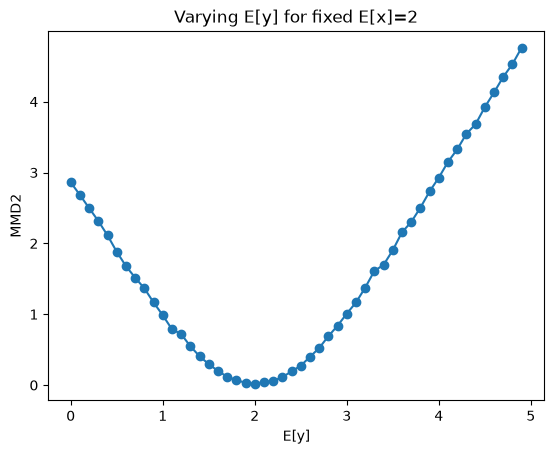

In [3]:
import matplotlib.pyplot as plt

mmd = []
xrange = tf.range(0, 5, 0.1).numpy()
for m in xrange:
    # instance of MMD2 class
    mmd2 = MMD2(kernel="energy")

    # initialize batches (B), number of samples (N,M)
    B = 40
    N, M = (50, 50)

    # draw for samples from two normals (x,y)
    x = tfd.Normal(loc=2, scale=0.5).sample((B, N))
    y = tfd.Normal(loc=m, scale=0.5).sample((B, M))

    # compute biased, squared mmd for both samples
    mmd_avg = mmd2(x, y)
    mmd.append(mmd_avg)

plt.plot(xrange, mmd, "-o")
plt.ylabel("MMD2")
plt.xlabel("E[y]")
plt.title("Varying E[y] for fixed E[x]=2")
plt.show()

#### Varying scale
Behavior of $MMD^2$ for varying scale but same difference between X and Y
Changes in scale do not affect the loss value

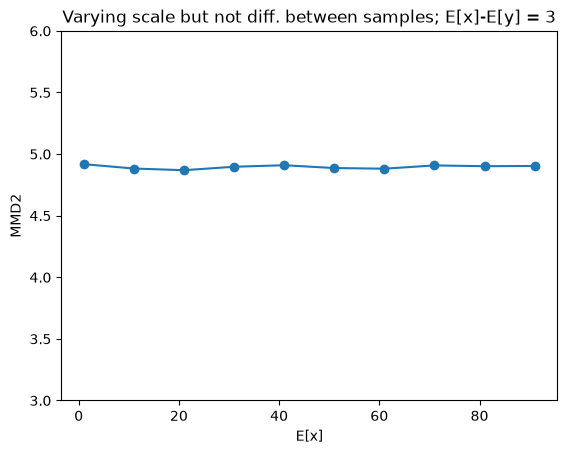

In [4]:
mmd = []
xrange = tf.range(1.0, 100.0, 10).numpy()
for x_m in xrange:
    # instance of MMD2 class
    mmd2 = MMD2(kernel="energy")

    # initialize batches (B), number of samples (N,M)
    B = 400
    N, M = (50, 50)
    diff = 3.0

    # draw for samples from two normals (x,y)
    x = tfd.Normal(loc=x_m, scale=0.5).sample((B, N))
    y = tfd.Normal(loc=float(x_m - diff), scale=0.5).sample((B, M))

    # compute biased, squared mmd for both samples
    mmd_avg = mmd2(x, y)
    mmd.append(mmd_avg)

plt.plot(xrange, mmd, "-o")
plt.ylabel("MMD2")
plt.xlabel("E[x]")
plt.title("Varying scale but not diff. between samples; E[x]-E[y] = 3")
plt.ylim(3, 6)
plt.show()